# RetailPulse - Step 1: Exploratory Data Analysis

Getting to know the data before modelling: how the tables connect, whether the data can be trusted, what patterns show up,
and which features the later models should use.

Data: a synthetic retail chain in Pakistan with 30 stores, 5,000 SKUs, 10,000 customers and ~10M sales lines (2022-2025).

## 0. Setup
DuckDB lets us query the 800 MB sales file with SQL without loading it into memory.

In [1]:
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.ticker as mt, seaborn as sns
from pathlib import Path
from IPython.display import display

pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'axes.titleweight': 'bold'})

ROOT = Path('..')
MAIN = ROOT / 'retail_clean_dataset'
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
CACHE = ROOT / 'data' / 'cache'; CACHE.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
def q(sql):  return con.sql(sql).df()
def save(name): plt.savefig(FIG / f'01_{name}.png', bbox_inches='tight')
millions = mt.FuncFormatter(lambda x, _: f'{x/1e6:,.0f}M')

### Convert the sales CSVs to Parquet (one-time)
Parquet is much smaller and faster to query than CSV.

In [2]:
csv = MAIN / 'sales_transactions.csv'
pq = CACHE / 'sales_main.parquet'
if not pq.exists():
    con.sql(f"COPY (SELECT * FROM read_csv_auto('{csv.as_posix()}')) TO '{pq.as_posix()}' (FORMAT parquet)")
print(f'{pq.stat().st_size/1e6:,.0f} MB parquet  (csv: {csv.stat().st_size/1e6:,.0f} MB)')

con.sql(f"CREATE OR REPLACE VIEW sales AS SELECT * FROM read_parquet('{pq.as_posix()}')")
for view, file in [('stores', 'store_master'), ('skus', 'sku_master'), ('customers', 'customer_master'),
                   ('promos', 'promotions'), ('inventory', 'inventory_snapshot'), ('flags', 'sku_inventory_flags')]:
    con.sql(f"CREATE OR REPLACE VIEW {view} AS SELECT * FROM read_csv_auto('{(MAIN / (file + '.csv')).as_posix()}')")

172 MB parquet  (csv: 803 MB)


## 1. Data inventory
Table sizes, missing values and duplicate rows.

In [3]:
TABLES = ['stores', 'skus', 'customers', 'promos', 'inventory', 'sales', 'flags']
rows = []
for t in TABLES:
    cols = q(f'DESCRIBE {t}').column_name.tolist()
    n = q(f'SELECT COUNT(*) n FROM {t}').n[0]
    nulls = q('SELECT ' + ', '.join(f'COUNT(*) - COUNT("{c}") AS "{c}"' for c in cols) + f' FROM {t}').iloc[0]
    dups = n - q(f'SELECT COUNT(*) n FROM (SELECT DISTINCT * FROM {t})').n[0]
    rows.append({'table': t, 'rows': n, 'columns': len(cols), 'duplicate_rows': dups,
                 'columns_with_nulls': ', '.join(f'{c} ({v:,})' for c, v in nulls.items() if v) or '-'})
overview = pd.DataFrame(rows)
overview

,table,rows,columns,duplicate_rows,columns_with_nulls
0,stores,30,5,0,-
1,skus,5000,7,0,-
2,customers,10000,7,0,-
3,promos,100,8,0,-
4,inventory,21228,6,0,-
5,sales,9972038,11,13019,"promo_id (7,881,687)"
6,flags,600,6,0,"window_start (400), window_end (400)"


`sales` is the fact table; `stores`, `skus`, `customers` and `promos` are dimensions. `inventory` is keyed by store x SKU,
and `flags` is the answer key for the inventory anomalies.

```
stores ─┐
skus ───┼──▶ sales (store_id, sku_id, customer_id, promo_id)
customers ┤
promos ─┘
stores + skus ──▶ inventory        skus ──▶ flags
```
The only nulls in `sales` are in `promo_id`, which just means no promotion.

## 2. Data quality checks

In [4]:
checks = {
 'Sales rows with unknown store':       "SELECT COUNT(*) FROM sales WHERE store_id NOT IN (SELECT store_id FROM stores)",
 'Sales rows with unknown SKU':         "SELECT COUNT(*) FROM sales WHERE sku_id NOT IN (SELECT sku_id FROM skus)",
 'Sales rows with unknown customer':    "SELECT COUNT(*) FROM sales WHERE customer_id NOT IN (SELECT cust_id FROM customers)",
 'Sales rows with unknown promo':       "SELECT COUNT(*) FROM sales WHERE promo_id IS NOT NULL AND promo_id NOT IN (SELECT promo_id FROM promos)",
 'total_value != qty*price*(1-disc)':   "SELECT COUNT(*) FROM sales WHERE ABS(total_value - quantity*unit_price*(1-discount_pct/100)) > 0.02",
 'Sale price differs from SKU list price': "SELECT COUNT(*) FROM sales s JOIN skus k USING(sku_id) WHERE ABS(s.unit_price - k.unit_price) > 0.01",
 'Quantity <= 0':                       "SELECT COUNT(*) FROM sales WHERE quantity <= 0",
 'Discount without promo_id':           "SELECT COUNT(*) FROM sales WHERE discount_pct > 0 AND promo_id IS NULL",
 'Promo used outside its date window':  "SELECT COUNT(*) FROM sales s JOIN promos p USING(promo_id) WHERE s.date NOT BETWEEN p.start_date AND p.end_date",
 'SKUs with cost >= price':             "SELECT COUNT(*) FROM skus WHERE cost_price >= unit_price",
 'Customers whose 1st purchase is before registration':
     "SELECT COUNT(*) FROM customers c JOIN (SELECT customer_id, MIN(date) d FROM sales GROUP BY 1) f ON c.cust_id = f.customer_id WHERE f.d < c.registration_date",
 'Customers with no purchases':         "SELECT COUNT(*) FROM customers WHERE cust_id NOT IN (SELECT DISTINCT customer_id FROM sales)",
 'Stores opened after 2022-01-01':      "SELECT COUNT(*) FROM stores WHERE opening_date > DATE '2022-01-01'",
 'Exact duplicate sales rows (extra copies)': "SELECT COUNT(*) - (SELECT COUNT(*) FROM (SELECT DISTINCT * FROM sales)) FROM sales",
 'Receipt + SKU pairs that appear more than once':
     "SELECT COUNT(*) FROM (SELECT receipt_id, sku_id FROM sales GROUP BY ALL HAVING COUNT(*) > 1)",
 'Receipts spanning >1 date/store/customer':
     "SELECT COUNT(*) FROM (SELECT receipt_id FROM sales GROUP BY 1 HAVING COUNT(DISTINCT date) > 1 OR COUNT(DISTINCT store_id) > 1 OR COUNT(DISTINCT customer_id) > 1)",
}
qc = pd.DataFrame([(k, int(con.sql(v).fetchone()[0])) for k, v in checks.items()], columns=['check', 'count'])
qc['status'] = np.where(qc['count'] == 0, 'OK', 'Review')
qc

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,check,count,status
0,Sales rows with unknown store,0,OK
1,Sales rows with unknown SKU,0,OK
2,Sales rows with unknown customer,0,OK
3,Sales rows with unknown promo,0,OK
4,total_value != qty*price*(1-disc),0,OK
5,Sale price differs from SKU list price,0,OK
6,Quantity <= 0,0,OK
7,Discount without promo_id,0,OK
8,Promo used outside its date window,0,OK
9,SKUs with cost >= price,0,OK


- Keys, prices and the `total_value` formula all check out, so the tables join cleanly.
- Some receipts have the same SKU on two lines, many of them exact copies. Summing quantity by receipt + SKU handles this either way.
- Many customers bought before their `registration_date`, so tenure should start from the first purchase instead.
- The dataset also has injected stockouts and slow movers, with an answer key (section 9).

## 3. Business overview (KPIs)

In [5]:
kpi = q('''
SELECT COUNT(*)                         AS line_items,
       COUNT(DISTINCT receipt_id)       AS baskets,
       SUM(quantity)                    AS units_sold,
       SUM(total_value)                 AS revenue,
       SUM(total_value)/COUNT(DISTINCT receipt_id) AS avg_basket_value,
       COUNT(*)*1.0/COUNT(DISTINCT receipt_id)     AS items_per_basket,
       AVG(quantity)                    AS avg_qty_per_line,
       MIN(date) AS first_date, MAX(date) AS last_date
FROM sales''')
gp = q('SELECT SUM(s.total_value - s.quantity*k.cost_price) gp FROM sales s JOIN skus k USING(sku_id)').gp[0]
kpi['gross_profit'] = gp; kpi['gross_margin_pct'] = 100 * gp / kpi.revenue
kpi.T.rename(columns={0: 'value'})

,value
line_items,9972038
baskets,5174631
units_sold,"18,750,830.00"
revenue,"10,917,737,293.39"
avg_basket_value,"2,109.86"
items_per_basket,1.93
avg_qty_per_line,1.88
first_date,2022-01-01 00:00:00
last_date,2025-12-31 00:00:00
gross_profit,"3,009,717,793.50"


## 4. Sales over time: trend and seasonality

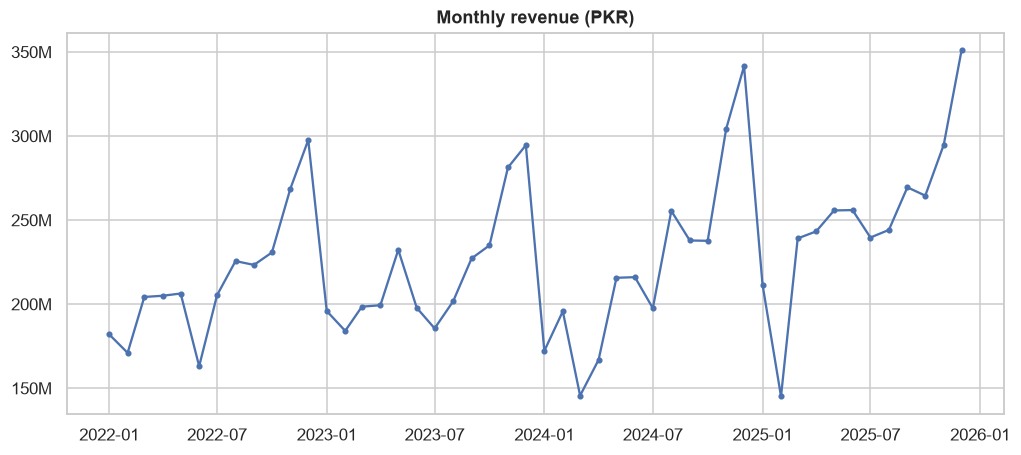

,yr,revenue,units,baskets,revenue_growth_pct,units_growth_pct,baskets_growth_pct
0,2022,"2,583,127,153.76","4,311,184.00",1187817,NaN,NaN,NaN
1,2023,"2,633,265,835.74","4,573,873.00",1261308,1.94,6.09,6.19
2,2024,"2,686,557,288.58","4,830,755.00",1330730,2.02,5.62,5.50
3,2025,"3,014,787,015.31","5,035,018.00",1394776,12.22,4.23,4.81


In [6]:
monthly = q('''SELECT DATE_TRUNC('month', date) AS month_start, SUM(total_value) revenue, SUM(quantity) units,
                      COUNT(DISTINCT receipt_id) baskets FROM sales GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots()
ax.plot(monthly.month_start, monthly.revenue, marker='o', ms=3)
ax.yaxis.set_major_formatter(millions); ax.set_title('Monthly revenue (PKR)'); ax.set_xlabel('')
save('04a_monthly_revenue'); plt.show()

yearly = q('''SELECT YEAR(date) yr, SUM(total_value) revenue, SUM(quantity) units, COUNT(DISTINCT receipt_id) baskets
              FROM sales GROUP BY 1 ORDER BY 1''')
for c in ['revenue', 'units', 'baskets']:
    yearly[c + '_growth_pct'] = yearly[c].pct_change() * 100
yearly

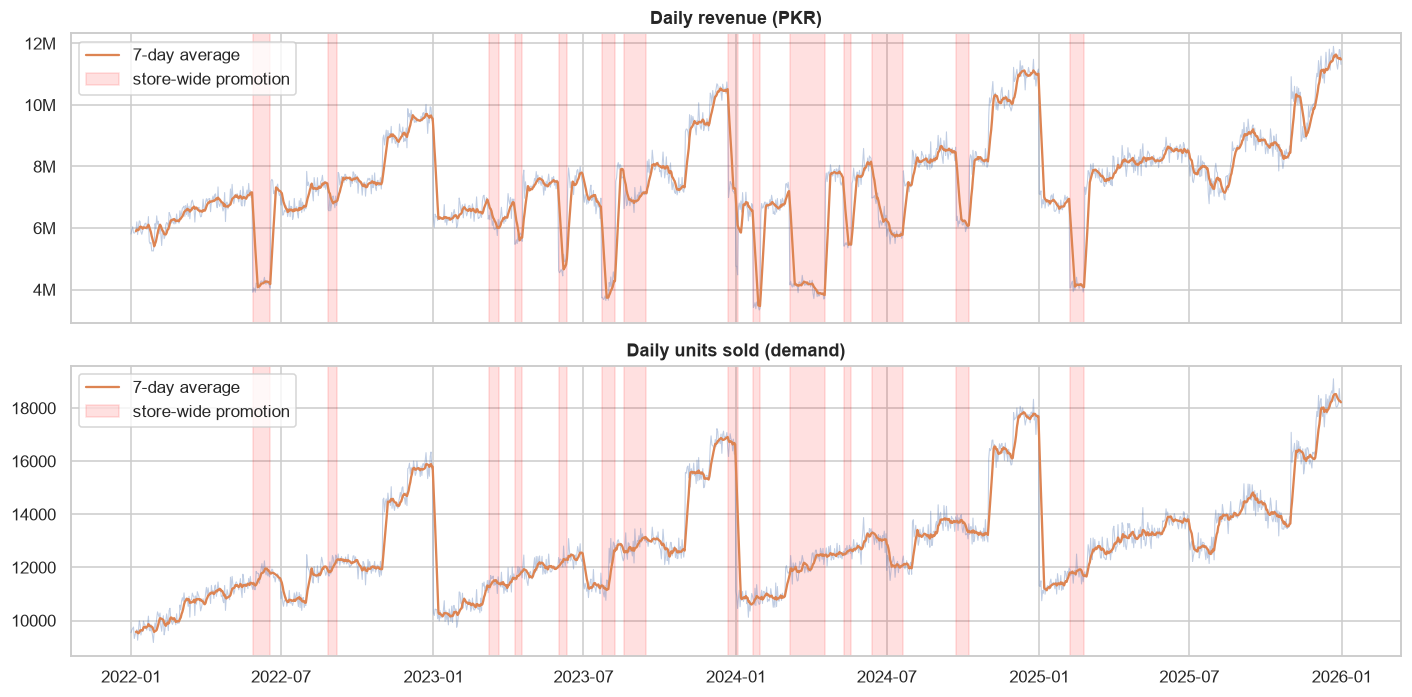

,revenue,units
normal day,"7,940,143.43","12,936.59"
store-wide promo day,"5,303,802.66","12,359.28"


On store-wide promo days revenue changes -33%, units change -4%  (259 such days)


In [7]:
daily = q('''SELECT date, SUM(total_value) revenue, SUM(quantity) units,
                    AVG(CASE WHEN promo_id IS NOT NULL THEN 1 ELSE 0 END) promo_share
             FROM sales GROUP BY 1 ORDER BY 1''')
daily['storewide_promo'] = daily.promo_share > 0.9          # days where (almost) every sale was discounted
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
for ax, col, title in [(axes[0], 'revenue', 'Daily revenue (PKR)'), (axes[1], 'units', 'Daily units sold (demand)')]:
    ax.plot(daily.date, daily[col], alpha=.35, lw=.7)
    ax.plot(daily.date, daily[col].rolling(7).mean(), lw=1.5, label='7-day average')
    ax.fill_between(daily.date, 0, 1, where=daily.storewide_promo, transform=ax.get_xaxis_transform(),
                    color='red', alpha=.12, label='store-wide promotion')
    ax.set_title(title); ax.legend(loc='upper left')
axes[0].yaxis.set_major_formatter(millions)
plt.tight_layout(); save('04b_daily_revenue_vs_units'); plt.show()

eff = daily.groupby('storewide_promo')[['revenue', 'units']].mean()
eff.index = ['normal day', 'store-wide promo day']
display(eff)
print(f"On store-wide promo days revenue changes {eff.revenue.iloc[1]/eff.revenue.iloc[0]-1:+.0%}, "
      f"units change {eff.units.iloc[1]/eff.units.iloc[0]-1:+.0%}  ({daily.storewide_promo.sum()} such days)")

The sharp revenue dips are store-wide promotions (often 30-50% off), not lost demand: revenue drops ~33% on those days
while units barely move. So the forecast target should be **units**, with the promo calendar as an input. These deep
discounts mostly give away margin (see section 8).

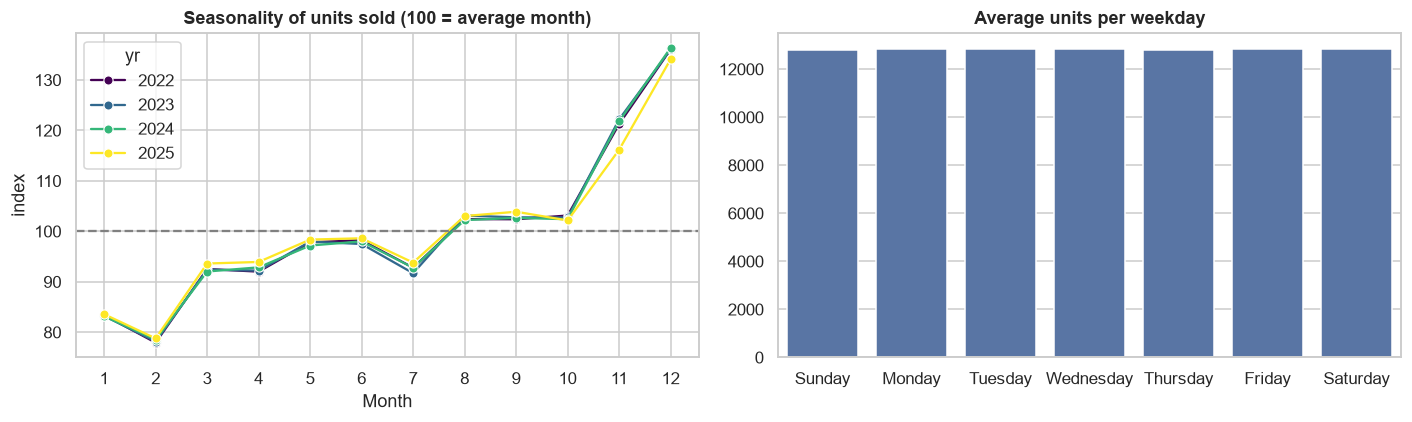

m,1,2,3,4,5,6,7,8,9,10,11,12
yr,,,,,,,,,,,,
2022,83.00,78.00,93.00,92.00,98.00,98.00,93.00,102.00,102.00,103.00,121.00,136.00
2023,83.00,78.00,92.00,92.00,98.00,97.00,92.00,103.00,103.00,103.00,122.00,136.00
2024,83.00,79.00,92.00,93.00,97.00,98.00,93.00,102.00,103.00,102.00,122.00,136.00
2025,84.00,79.00,94.00,94.00,98.00,99.00,94.00,103.00,104.00,102.00,116.00,134.00


,0,1,2,3,4,5,6
day_name,Sunday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday
index,99.78,100.01,100.18,100.04,99.79,100.05,100.16


In [8]:
seas = q('''SELECT YEAR(date) yr, MONTH(date) m, SUM(quantity) units FROM sales GROUP BY 1,2''')
seas['index'] = seas.units / seas.groupby('yr').units.transform('mean') * 100   # 100 = average month of that year
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=seas, x='m', y='index', hue='yr', palette='viridis', marker='o', ax=axes[0])
axes[0].axhline(100, color='grey', ls='--'); axes[0].set(title='Seasonality of units sold (100 = average month)', xlabel='Month', xticks=range(1, 13))

dow = q('''SELECT DAYOFWEEK(date) d, DAYNAME(date) AS day_name, SUM(quantity)/COUNT(DISTINCT date) units_per_day
           FROM sales GROUP BY 1,2 ORDER BY 1''')
sns.barplot(data=dow, x='day_name', y='units_per_day', ax=axes[1], color='C0')
axes[1].set(title='Average units per weekday', xlabel='', ylabel='')
plt.tight_layout(); save('04c_seasonality'); plt.show()
display(seas.pivot(index='yr', columns='m', values='index').round(0))
dow.assign(index=dow.units_per_day / dow.units_per_day.mean() * 100)[['day_name', 'index']].T

- Strong, stable yearly pattern: February is ~20% below an average month, November +20% and December +35%.
- Units grow a steady 4-6% a year. Revenue jumped 12% in 2025 mainly because there was only one store-wide discount period.
- No weekday effect (every weekday is within ±1%).
- Demand moves in monthly steps, so month of year is the most useful calendar feature.

## 5. Stores: where revenue is made

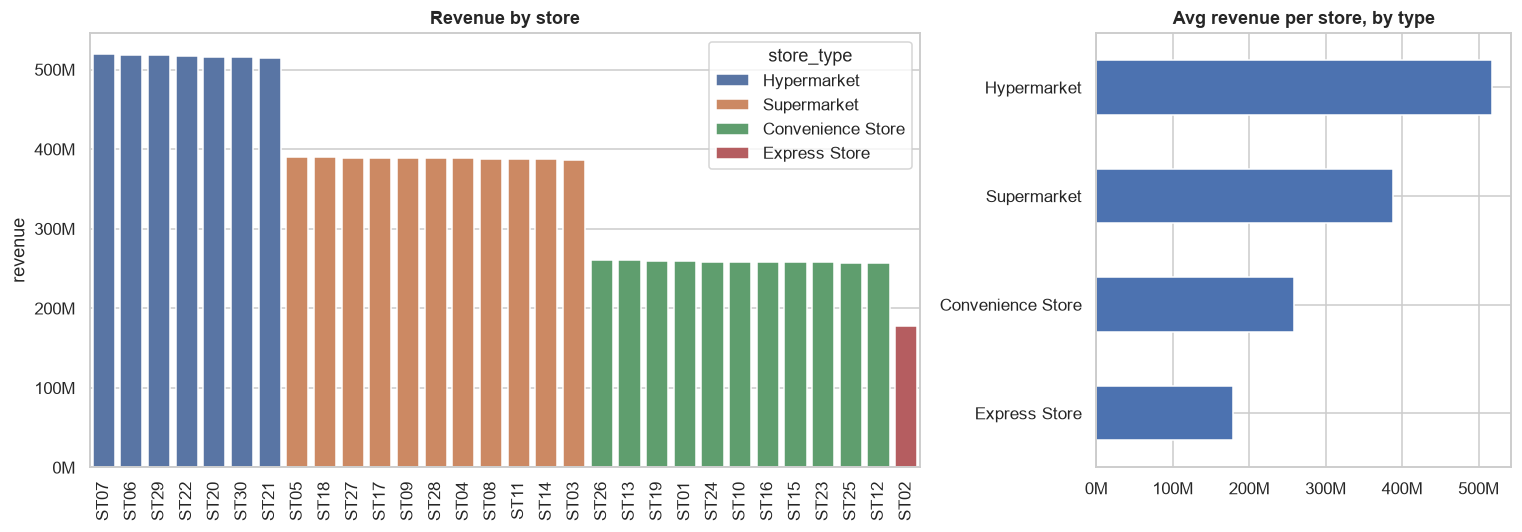

,stores,revenue_per_store,basket_value
store_type,,,
Express Store,1,"178,370,967.78","2,122.66"
Convenience Store,11,"258,882,835.02","2,109.76"
Supermarket,11,"388,396,145.64","2,110.03"
Hypermarket,7,"517,042,505.48","2,109.11"


,stores,revenue
city,,
Karachi,5,"2,074,697,147.15"
Multan,4,"1,679,924,076.46"
Islamabad,4,"1,341,985,011.62"
Peshawar,2,"1,034,633,270.07"
Sialkot,3,"1,033,078,346.59"
Quetta,3,"905,241,452.59"
Sukkur,2,"776,360,845.84"
Rawalpindi,2,"647,435,574.99"
Lahore,2,"519,775,001.40"


In [9]:
st = q('''SELECT st.store_id, st.store_name, st.city, st.store_type, SUM(s.total_value) revenue,
                 COUNT(DISTINCT s.receipt_id) baskets, SUM(s.total_value)/COUNT(DISTINCT s.receipt_id) basket_value
          FROM sales s JOIN stores st USING(store_id) GROUP BY ALL ORDER BY revenue DESC''')
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [2, 1]})
sns.barplot(data=st, x='store_id', y='revenue', hue='store_type', dodge=False, ax=axes[0])
axes[0].yaxis.set_major_formatter(millions); axes[0].tick_params(axis='x', rotation=90)
axes[0].set(title='Revenue by store', xlabel='')
by_type = st.groupby('store_type').agg(stores=('store_id', 'count'), revenue_per_store=('revenue', 'mean'),
                                       basket_value=('basket_value', 'mean')).sort_values('revenue_per_store')
by_type.revenue_per_store.plot.barh(ax=axes[1], color='C0'); axes[1].xaxis.set_major_formatter(millions)
axes[1].set(title='Avg revenue per store, by type', ylabel='')
plt.tight_layout(); save('05_stores'); plt.show()
display(by_type)
st.groupby('city').agg(stores=('store_id', 'count'), revenue=('revenue', 'sum')).sort_values('revenue', ascending=False)

## 6. Products: categories, margins and bestsellers

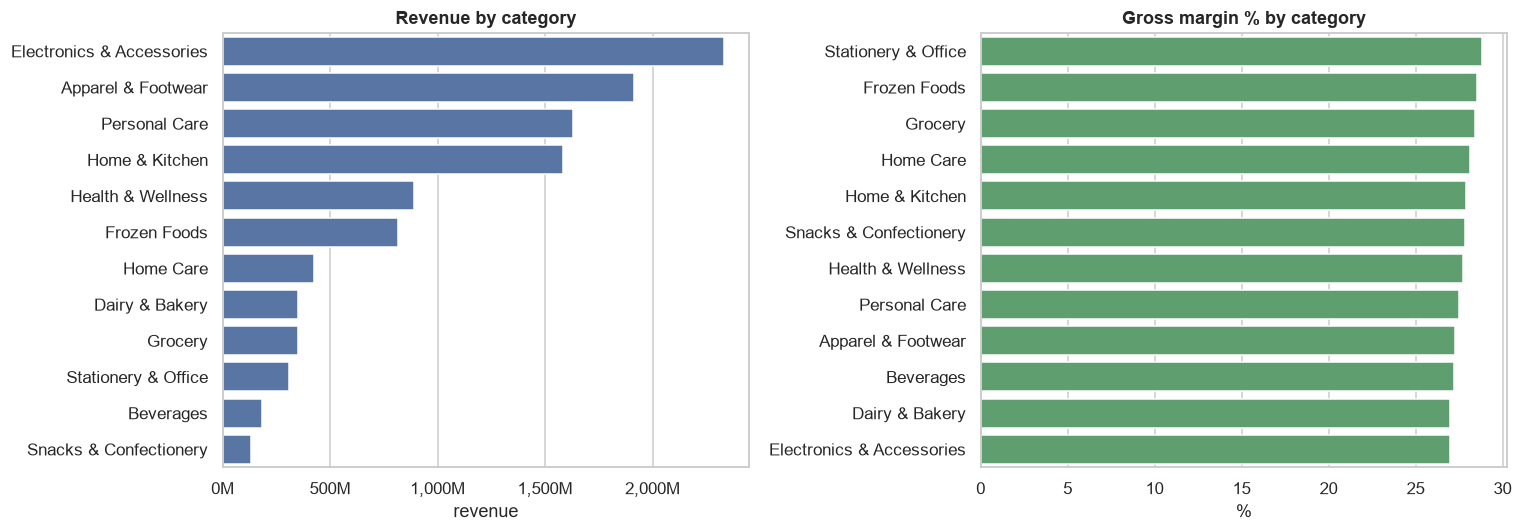

,category,revenue,units,gross_profit,skus,margin_pct,revenue_share_pct
0,Electronics & Accessories,"2,333,273,677.87","1,381,227.00","629,427,737.44",394,26.98,21.37
1,Apparel & Footwear,"1,914,751,093.15","1,225,678.00","522,294,226.53",410,27.28,17.54
2,Personal Care,"1,630,884,911.28","2,721,022.00","448,079,496.18",410,27.47,14.94
3,Home & Kitchen,"1,583,147,445.90","1,406,271.00","441,255,602.40",390,27.87,14.50
4,Health & Wellness,"890,123,268.46","1,257,204.00","246,712,099.04",396,27.72,8.15
5,Frozen Foods,"815,648,084.35","1,552,581.00","232,498,330.31",422,28.50,7.47
6,Home Care,"423,414,441.48","1,558,517.00","119,086,472.97",425,28.13,3.88
7,Dairy & Bakery,"351,873,910.83","1,721,948.00","95,000,157.20",428,27.00,3.22
8,Grocery,"350,019,046.67","1,494,368.00","99,495,701.49",395,28.43,3.21
9,Stationery & Office,"310,496,680.04","1,747,842.00","89,524,593.58",459,28.83,2.84


In [10]:
cat = q('''SELECT k.category, SUM(s.total_value) revenue, SUM(s.quantity) units,
                  SUM(s.total_value - s.quantity*k.cost_price) gross_profit, COUNT(DISTINCT k.sku_id) skus
           FROM sales s JOIN skus k USING(sku_id) GROUP BY 1 ORDER BY revenue DESC''')
cat['margin_pct'] = cat.gross_profit / cat.revenue * 100
cat['revenue_share_pct'] = cat.revenue / cat.revenue.sum() * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=cat, y='category', x='revenue', ax=axes[0], color='C0')
axes[0].xaxis.set_major_formatter(millions); axes[0].set(title='Revenue by category', ylabel='')
sns.barplot(data=cat.sort_values('margin_pct', ascending=False), y='category', x='margin_pct', ax=axes[1], color='C2')
axes[1].set(title='Gross margin % by category', ylabel='', xlabel='%')
plt.tight_layout(); save('06a_categories'); plt.show()
cat

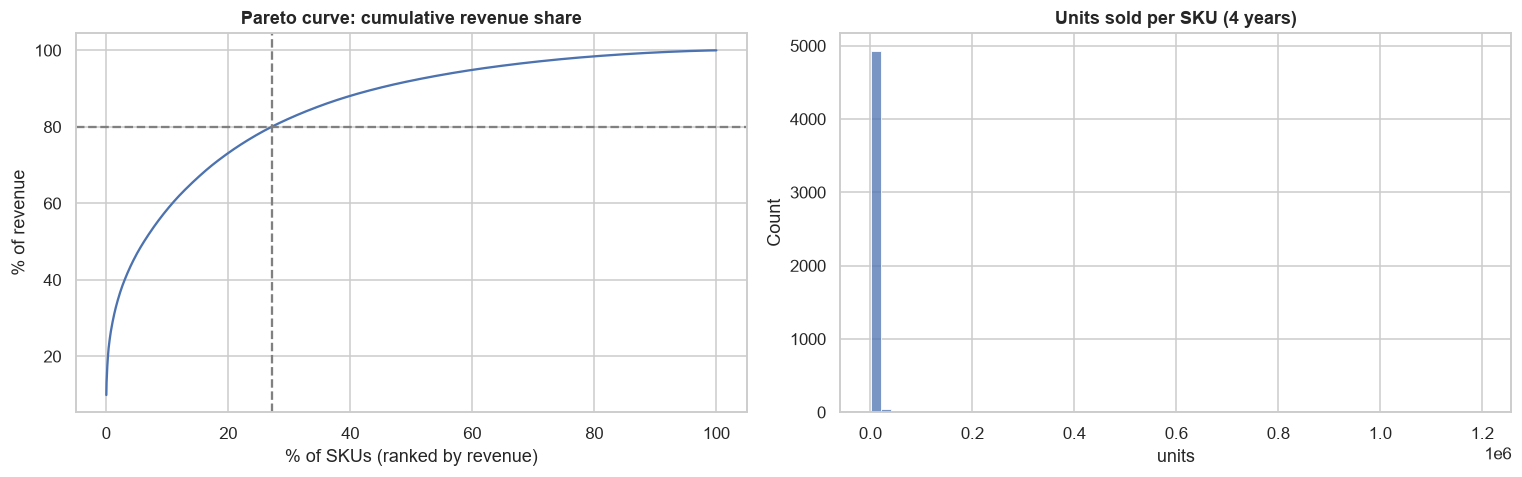

Top 20% of SKUs = 73.2% of revenue;  1,356 SKUs (27.1%) make 80% of revenue
Units per SKU: min 1,105, median 1,969, max 1,197,375


,sku_id,sku_name,category,unit_price,units,revenue
0,SKU04321,EliteHome Hair Care Pack of 6,Personal Care,961.30,"1,197,375.00","1,079,871,044.68"
1,SKU03727,QuickBite Mobile Accessories 2kg,Electronics & Accessories,"1,660.93","168,010.00","261,888,277.84"
2,SKU04329,SoftTouch Cookware 2kg,Home & Kitchen,"2,452.07","41,379.00","94,754,136.50"
3,SKU04596,ValueChoice Eggs Pack of 6,Dairy & Bakery,335.55,"284,552.00","89,189,686.19"
4,SKU01371,PureLife Cookware 1L,Home & Kitchen,"1,277.61","70,665.00","84,147,919.58"
5,SKU03053,PremiumSelect Kids Wear Family Pack,Apparel & Footwear,"4,086.72","21,925.00","84,109,344.32"
6,SKU01189,PureLife Footwear 500g,Apparel & Footwear,"2,299.80","32,639.00","70,319,166.18"
7,SKU04551,DailyBest Cookware Small,Home & Kitchen,"2,498.23","29,853.00","69,225,870.82"
8,SKU04157,PremiumSelect Small Appliances 1L,Electronics & Accessories,"2,678.35","27,457.00","69,135,499.35"
9,SKU04571,EliteHome Ready Meals 250g,Frozen Foods,868.52,"76,342.00","62,532,292.16"


In [11]:
sku = q('''SELECT k.sku_id, k.sku_name, k.category, k.unit_price, SUM(s.quantity) units, SUM(s.total_value) revenue
           FROM skus k LEFT JOIN sales s USING(sku_id) GROUP BY ALL ORDER BY revenue DESC''')
sku['cum_share'] = sku.revenue.cumsum() / sku.revenue.sum()
sku['sku_rank_pct'] = np.arange(1, len(sku) + 1) / len(sku)
top20 = sku.loc[sku.sku_rank_pct <= .2, 'revenue'].sum() / sku.revenue.sum()
n80 = (sku.cum_share < .8).sum() + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(sku.sku_rank_pct * 100, sku.cum_share * 100)
axes[0].axhline(80, ls='--', c='grey'); axes[0].axvline(n80 / len(sku) * 100, ls='--', c='grey')
axes[0].set(title='Pareto curve: cumulative revenue share', xlabel='% of SKUs (ranked by revenue)', ylabel='% of revenue')
sns.histplot(sku.units, bins=60, ax=axes[1]); axes[1].set(title='Units sold per SKU (4 years)', xlabel='units')
plt.tight_layout(); save('06b_pareto'); plt.show()
print(f'Top 20% of SKUs = {top20:.1%} of revenue;  {n80:,} SKUs ({n80/len(sku):.1%}) make 80% of revenue')
print(f'Units per SKU: min {sku.units.min():,.0f}, median {sku.units.median():,.0f}, max {sku.units.max():,.0f}')
display(sku.head(10)[['sku_id', 'sku_name', 'category', 'unit_price', 'units', 'revenue']])

One SKU (`SKU04321`) sells over a million units, about 10% of all revenue, while the median SKU sells ~2,000 units in
4 years. Top SKUs can be forecast one by one; the long tail is better handled at category or store level.

## 7. Customers: who buys, how often and through which channel

In [12]:
# one row per customer
END = q("SELECT MAX(date) d FROM sales").d[0]
rfm = q(f'''
SELECT c.cust_id, c.age, c.gender, c.city, c.loyalty_segment, c.preferred_channel,
       DATE_DIFF('day', MAX(s.date), DATE '{END:%Y-%m-%d}') AS recency_days,
       COUNT(DISTINCT s.receipt_id)                       AS frequency,
       SUM(s.total_value)                                 AS monetary,
       SUM(s.total_value)/COUNT(DISTINCT s.receipt_id)    AS avg_basket_value,
       DATE_DIFF('day', MIN(s.date), MAX(s.date))         AS active_span_days,
       AVG(CASE WHEN s.channel = c.preferred_channel THEN 1 ELSE 0 END) AS pref_channel_share,
       AVG(CASE WHEN s.promo_id IS NOT NULL THEN 1 ELSE 0 END)          AS promo_share,
       COUNT(DISTINCT s.store_id)                         AS stores_used
FROM customers c JOIN sales s ON s.customer_id = c.cust_id GROUP BY ALL''')
rfm.describe().T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,count,mean,std,min,25%,50%,75%,max
age,"10,000.00",37.70,12.19,18.00,29.00,37.00,46.00,80.00
recency_days,"10,000.00",1.85,2.51,0.00,0.00,1.00,3.00,30.00
frequency,"10,000.00",517.46,231.60,255.00,333.00,457.00,680.25,"1,178.00"
monetary,"10,000.00","1,091,773.73","491,707.16","486,507.43","707,588.48","955,913.64","1,411,571.55","2,589,816.18"
avg_basket_value,"10,000.00","2,109.82",114.40,"1,644.64","2,034.51","2,108.00","2,184.34","2,535.59"
active_span_days,"10,000.00","1,454.23",5.71,"1,395.00","1,452.00","1,456.00","1,458.00","1,460.00"
pref_channel_share,"10,000.00",0.82,0.05,0.66,0.78,0.84,0.87,0.93
promo_share,"10,000.00",0.21,0.02,0.12,0.20,0.21,0.22,0.29
stores_used,"10,000.00",30.00,0.06,29.00,30.00,30.00,30.00,30.00


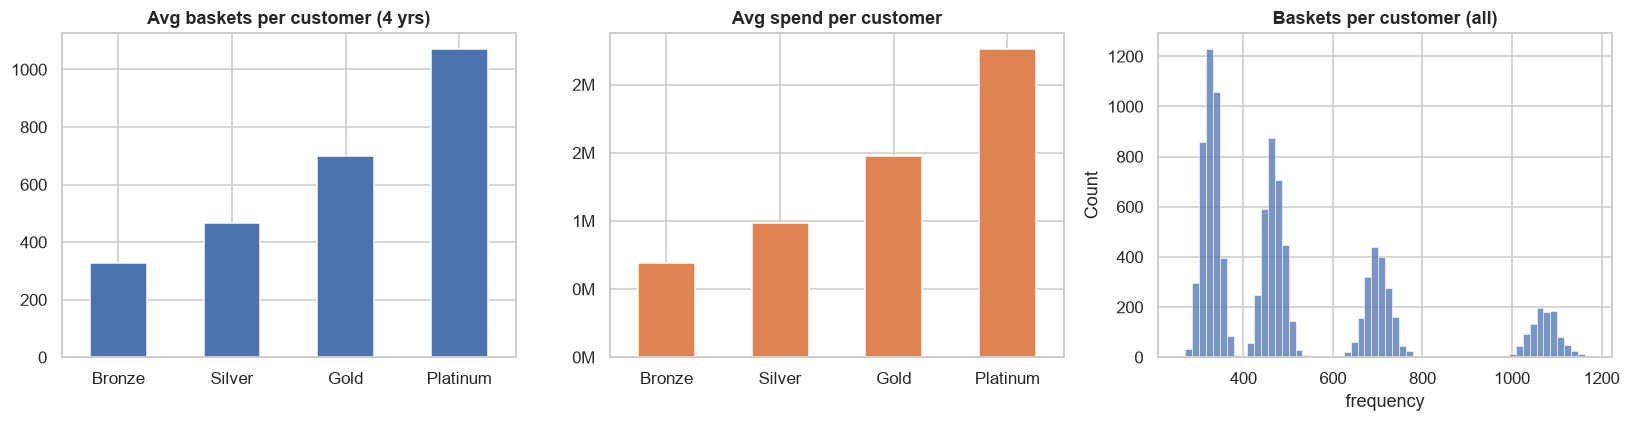

,customers,avg_baskets,avg_spend,avg_basket_value,avg_recency_days
loyalty_segment,,,,,
Bronze,3969,326.40,"688,413.58","2,109.09",2.74
Silver,3106,466.99,"986,142.32","2,111.57",1.67
Gold,1905,700.48,"1,476,564.93","2,108.06",1.00
Platinum,1020,"1,072.80","2,264,323.09","2,110.60",0.52


Customers shop on their preferred channel 82.5% of the time
Top 20% of customers by spend = 35.0% of revenue


In [13]:
order = ['Bronze', 'Silver', 'Gold', 'Platinum']
seg = rfm.groupby('loyalty_segment').agg(customers=('cust_id', 'count'), avg_baskets=('frequency', 'mean'),
        avg_spend=('monetary', 'mean'), avg_basket_value=('avg_basket_value', 'mean'),
        avg_recency_days=('recency_days', 'mean')).reindex(order)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
seg.avg_baskets.plot.bar(ax=axes[0], color='C0', title='Avg baskets per customer (4 yrs)')
seg.avg_spend.plot.bar(ax=axes[1], color='C1', title='Avg spend per customer'); axes[1].yaxis.set_major_formatter(millions)
sns.histplot(rfm.frequency, bins=60, ax=axes[2]); axes[2].set_title('Baskets per customer (all)')
for a in axes[:2]: a.tick_params(axis='x', rotation=0); a.set_xlabel('')
plt.tight_layout(); save('07b_loyalty'); plt.show()
display(seg)
print(f"Customers shop on their preferred channel {rfm.pref_channel_share.mean():.1%} of the time")
print(f"Top 20% of customers by spend = {rfm.monetary.nlargest(len(rfm)//5).sum()/rfm.monetary.sum():.1%} of revenue")

### Is there churn in this data?
Checking recency and the longest gap between purchases.

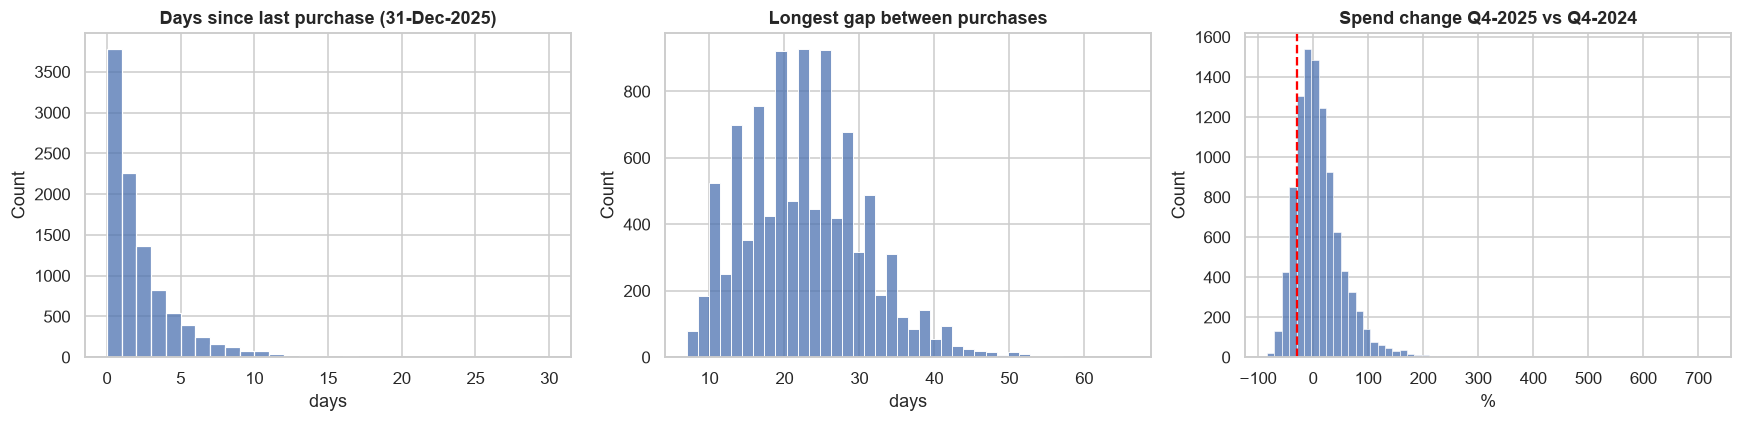

Max days since last purchase: 30  |  average gap between shopping days: 3.8 days
Longest gap any customer ever had between purchases: 66 days
Customers whose Q4 spend fell by more than 20% year-on-year: 23.7%
Customers whose Q4 spend fell by more than 30% year-on-year: 14.2%
Customers whose Q4 spend fell by more than 40% year-on-year: 7.4%


In [14]:
gaps = q('''WITH d AS (SELECT DISTINCT customer_id, date FROM sales),
                 g AS (SELECT customer_id,
                              DATE_DIFF('day', LAG(date) OVER (PARTITION BY customer_id ORDER BY date), date) gap FROM d)
            SELECT customer_id, MAX(gap) max_gap_days, AVG(gap) avg_gap_days FROM g GROUP BY 1''')
# Q4 2025 vs Q4 2024 spend per customer (same season)
yoy = q('''SELECT customer_id,
                  SUM(total_value) FILTER (WHERE date BETWEEN '2024-10-01' AND '2024-12-31') q4_2024,
                  SUM(total_value) FILTER (WHERE date BETWEEN '2025-10-01' AND '2025-12-31') q4_2025
           FROM sales GROUP BY 1''')
yoy['change_pct'] = (yoy.q4_2025 / yoy.q4_2024 - 1) * 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(rfm.recency_days, bins=30, ax=axes[0]); axes[0].set(title='Days since last purchase (31-Dec-2025)', xlabel='days')
sns.histplot(gaps.max_gap_days, bins=40, ax=axes[1]); axes[1].set(title='Longest gap between purchases', xlabel='days')
sns.histplot(yoy.change_pct, bins=60, ax=axes[2]); axes[2].axvline(-30, c='red', ls='--')
axes[2].set(title='Spend change Q4-2025 vs Q4-2024', xlabel='%')
plt.tight_layout(); save('07c_churn_check'); plt.show()

print(f"Max days since last purchase: {rfm.recency_days.max()}  |  average gap between shopping days: {gaps.avg_gap_days.mean():.1f} days")
print(f"Longest gap any customer ever had between purchases: {gaps.max_gap_days.max()} days")
for t in [-20, -30, -40]:
    print(f"Customers whose Q4 spend fell by more than {-t}% year-on-year: {(yoy.change_pct < t).mean():.1%}")

In [15]:
# are customers actually leaving?
act = q('''SELECT DATE_TRUNC('quarter', date) AS qtr, COUNT(DISTINCT customer_id) active_customers,
                  COUNT(DISTINCT receipt_id)*1.0/COUNT(DISTINCT customer_id) baskets_per_active
           FROM sales GROUP BY 1 ORDER BY 1''')
first = q("SELECT DATE_TRUNC('quarter', MIN(date)) AS qtr, COUNT(*) new_customers FROM sales GROUP BY customer_id")
act = act.merge(first.groupby('qtr').size().rename('new_customers').reset_index(), on='qtr', how='left').fillna(0)
ch = q("SELECT channel, COUNT(*) lines, SUM(total_value) revenue, SUM(total_value)/COUNT(DISTINCT receipt_id) basket_value FROM sales GROUP BY 1 ORDER BY revenue DESC")
ch['revenue_share_pct'] = ch.revenue / ch.revenue.sum() * 100
display(act); display(ch)

,qtr,active_customers,baskets_per_active,new_customers
0,2022-01-01,10000,25.16,"10,000.00"
1,2022-04-01,10000,28.49,0.00
2,2022-07-01,10000,29.44,0.00
3,2022-10-01,10000,35.69,0.00
4,2023-01-01,10000,26.69,0.00
5,2023-04-01,10000,30.20,0.00
6,2023-07-01,10000,31.26,0.00
7,2023-10-01,10000,37.99,0.00
8,2024-01-01,10000,28.16,0.00
9,2024-04-01,10000,31.94,0.00


,channel,lines,revenue,basket_value,revenue_share_pct
0,In-Store,5511403,"6,032,995,509.21","2,108.96",55.26
1,Online,2966045,"3,246,583,534.08","2,110.79",29.74
2,Mobile App,1494590,"1,638,158,250.10","2,111.34",15.00


Nobody leaves. All 10,000 customers buy in every quarter, shop at all 30 stores, and no one goes more than about a month
without buying, so a "stopped buying" label would have no positive cases.

Churn will instead be defined as a **drop in spend**: next quarter's spend more than ~30% below the same quarter last year.
The histogram shows enough variation for that to work.

## 8. Promotions: do discounts change behaviour?

In [16]:
pr = q('''SELECT p.promo_type, p.target_type, COUNT(DISTINCT p.promo_id) promos, COUNT(s.sku_id) lines,
                 AVG(s.discount_pct) avg_disc, SUM(s.quantity*s.unit_price - s.total_value) discount_given
          FROM promos p LEFT JOIN sales s USING(promo_id) GROUP BY ALL ORDER BY lines DESC''')
display(pr)
comp = q('''SELECT promo_id IS NOT NULL AS on_promo, COUNT(*) lines, AVG(quantity) avg_qty,
                   AVG(total_value) avg_line_value, SUM(total_value) revenue FROM sales GROUP BY 1''')
comp['share_of_lines_pct'] = comp.lines / comp.lines.sum() * 100
comp

,promo_type,target_type,promos,lines,avg_disc,discount_given
0,BOGO,All,3,418625,27.26,"133,735,377.93"
1,Percentage Discount,All,5,412053,34.91,"167,307,816.31"
2,Bundle Offer,All,6,356717,30.74,"129,351,522.90"
3,Flat Discount,All,3,301368,23.19,"80,258,074.32"
4,Clearance,All,2,140790,49.15,"81,137,969.16"
5,Clearance,Category,11,113679,26.09,"35,203,526.32"
6,Bundle Offer,Category,9,89656,30.37,"38,454,626.79"
7,Percentage Discount,Category,9,83226,28.84,"24,343,592.96"
8,BOGO,Category,7,60822,21.77,"19,562,471.19"
9,Flat Discount,Brand,8,35584,19.48,"8,818,336.36"


,on_promo,lines,avg_qty,avg_line_value,revenue,share_of_lines_pct
0,True,2090351,1.88,833.46,"1,742,233,472.42",20.96
1,False,7881687,1.88,"1,164.15","9,175,503,820.97",79.04


In [17]:
# store-wide promos: units/day during the promo vs the 14 days before
units_by_day = daily.set_index('date').units
rows = []
for p in q("SELECT * FROM promos WHERE target_type = 'All' ORDER BY start_date").itertuples():
    s, e = pd.Timestamp(p.start_date), pd.Timestamp(p.end_date)
    during = units_by_day[s:e].mean()
    before = units_by_day[s - pd.Timedelta(days=14): s - pd.Timedelta(days=1)].mean()
    rows.append({'promo_id': p.promo_id, 'promo_name': p.promo_name, 'start': s.date(), 'days': (e - s).days + 1,
                 'promo_type': p.promo_type, 'discount_pct': p.discount_pct, 'unit_lift_pct': (during / before - 1) * 100})
lift = pd.DataFrame(rows)
display(lift)
print(f"Average unit lift of store-wide promos: {lift.unit_lift_pct.mean():+.1f}%  "
      f"(correlation between discount depth and lift: {lift.discount_pct.corr(lift.unit_lift_pct):+.2f})")

,promo_id,promo_name,start,days,promo_type,discount_pct,unit_lift_pct
0,PROMO022,Clearance Deal Days,2022-05-28,22,Percentage Discount,42.80,3.22
1,PROMO033,Super Deal Days,2022-08-27,12,Bundle Offer,9.00,1.76
2,PROMO002,Summer Savings Event,2023-03-09,13,Bundle Offer,7.00,4.66
3,PROMO046,Anniversary Deal Days,2023-04-09,10,BOGO,21.90,2.50
4,PROMO028,Back to School Fest,2023-04-12,7,Percentage Discount,19.80,2.76
5,PROMO040,Anniversary Discount Days,2023-06-01,10,Percentage Discount,39.90,2.47
6,PROMO034,Winter Discount Days,2023-06-04,8,Bundle Offer,23.40,2.20
7,PROMO030,Back to School Offer,2023-07-23,17,Clearance,49.70,4.62
8,PROMO010,Spring Fest,2023-08-19,28,BOGO,12.70,1.08
9,PROMO043,Year-End Offer,2023-12-23,12,Percentage Discount,29.90,-10.26


Average unit lift of store-wide promos: +1.0%  (correlation between discount depth and lift: +0.22)


Promoted lines have the same average quantity as normal ones, and store-wide promotions lift units only slightly at any
discount depth. Discounts mainly cut revenue and margin, so promo features matter more for revenue than for unit forecasts.

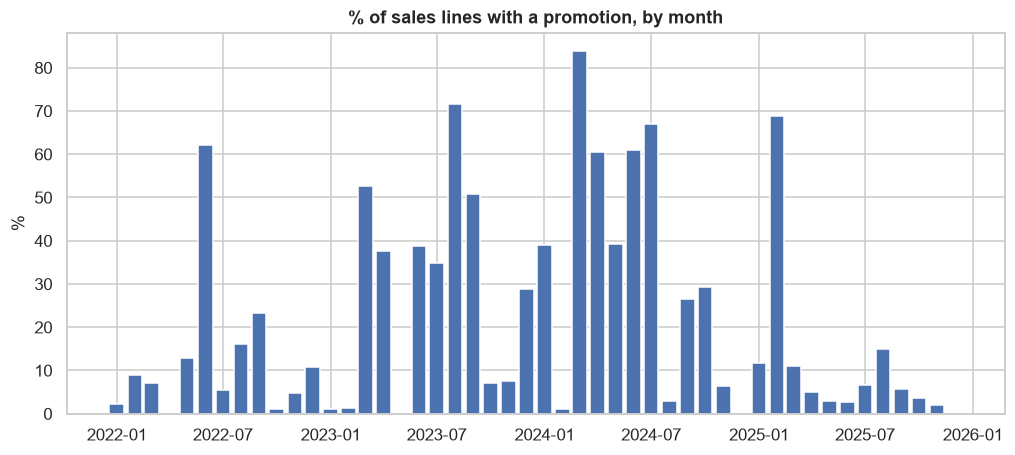

In [18]:
pm = q('''SELECT DATE_TRUNC('month', date) AS month_start, AVG(CASE WHEN promo_id IS NOT NULL THEN 1 ELSE 0 END)*100 promo_share
          FROM sales GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(); ax.bar(pm.month_start, pm.promo_share, width=25)
ax.set(title='% of sales lines with a promotion, by month', ylabel='%'); save('08_promo_share'); plt.show()

## 9. Inventory: stock health and the anomaly answer key

Inventory rows: 21,228  covering 4,481 SKUs and 30 stores (of 150,000 possible store x SKU pairs)


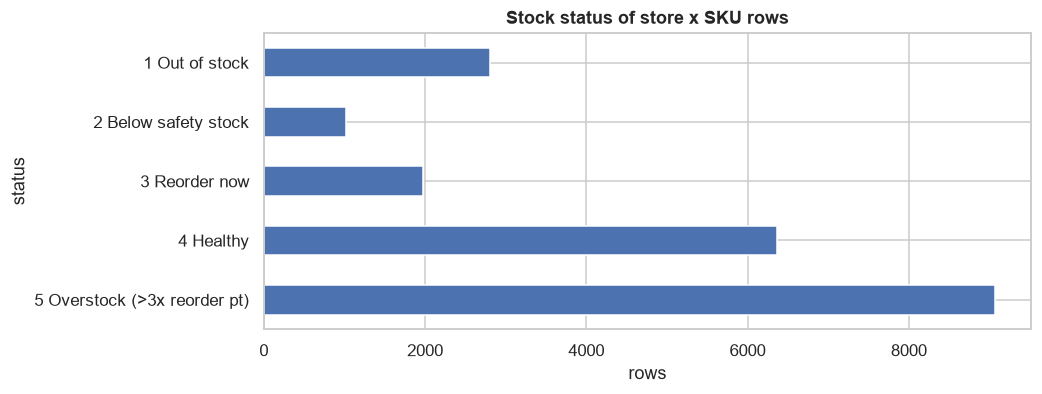

status
1 Out of stock                 13.20
2 Below safety stock            4.80
3 Reorder now                   9.30
4 Healthy                      30.00
5 Overstock (>3x reorder pt)   42.70
Name: % of rows, dtype: float64

In [19]:
inv = q('''SELECT *, CASE WHEN stock_on_hand = 0 THEN '1 Out of stock'
                          WHEN stock_on_hand < safety_stock THEN '2 Below safety stock'
                          WHEN stock_on_hand < reorder_point THEN '3 Reorder now'
                          WHEN stock_on_hand > 3*reorder_point THEN '5 Overstock (>3x reorder pt)'
                          ELSE '4 Healthy' END status
           FROM inventory''')
print(f"Inventory rows: {len(inv):,}  covering {inv.sku_id.nunique():,} SKUs and {inv.store_id.nunique()} stores "
      f"(of {30*5000:,} possible store x SKU pairs)")
status = inv.status.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.5)); status.plot.barh(ax=ax, color='C0'); ax.invert_yaxis()
ax.set(title='Stock status of store x SKU rows', xlabel='rows'); save('10a_stock_status'); plt.show()
(status / len(inv) * 100).round(1).rename('% of rows')

In [20]:
fl = q('''SELECT flag, COUNT(*) skus, AVG(LEN(STRING_SPLIT(affected_stores, ';'))) avg_stores_affected,
                 MIN(window_start) earliest_start, MAX(window_end) latest_end,
                 AVG(DATE_DIFF('day', window_start, window_end)) avg_window_days
          FROM flags GROUP BY 1''')
display(fl)
# Where do flagged SKUs sit in the sales ranking?
rank = sku[['sku_id', 'units']].assign(rank=np.arange(1, len(sku) + 1))
rank = rank.sort_values('units', ascending=False).assign(volume_rank=np.arange(1, len(sku) + 1))
flagged = q("SELECT sku_id, flag FROM flags").merge(rank, on='sku_id')
flagged.groupby('flag').volume_rank.describe()

,flag,skus,avg_stores_affected,earliest_start,latest_end,avg_window_days
0,SLOW_MOVER,400,22.73,NaT,NaT,NaN
1,STOCKOUT_RISK,200,13.69,2025-10-17,2025-12-31,18.68


,count,mean,std,min,25%,50%,75%,max
flag,,,,,,,,
SLOW_MOVER,400.00,"4,707.97",216.16,"4,040.00","4,553.75","4,755.50","4,885.25","5,000.00"
STOCKOUT_RISK,200.00,100.50,57.88,1.00,50.75,100.50,150.25,200.00


- The snapshot covers ~21k of 150k possible store x SKU pairs. A large share is overstocked (>3x reorder point) and some are out of stock.
- `STOCKOUT_RISK` SKUs are the top 200 sellers and `SLOW_MOVER` SKUs come from the bottom ~1,000. All stockout windows are in the last ~75 days of 2025, which overlaps the forecasting test period.

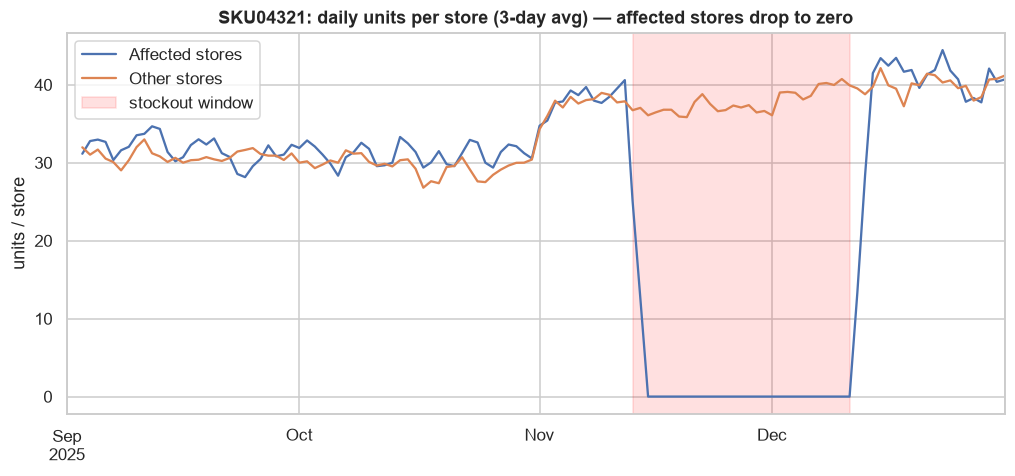

In [21]:
# one injected stockout: affected vs unaffected stores
ex = q("SELECT sku_id, affected_stores, window_start, window_end FROM flags WHERE flag='STOCKOUT_RISK' LIMIT 1").iloc[0]
aff = ex.affected_stores.split(';')
w = q(f'''SELECT date, CASE WHEN store_id IN ({",".join(f"'{s}'" for s in aff)}) THEN 'Affected stores' ELSE 'Other stores' END grp,
                 SUM(quantity) units
          FROM sales WHERE sku_id = '{ex.sku_id}' AND date >= DATE '2025-09-01' GROUP BY ALL ORDER BY 1''')
w['units_per_store'] = w.units / np.where(w.grp == 'Affected stores', len(aff), 30 - len(aff))
w = w.pivot(index='date', columns='grp', values='units_per_store').fillna(0)   # missing day = zero sales
fig, ax = plt.subplots()
w.rolling(3).mean().plot(ax=ax)
ax.axvspan(ex.window_start, ex.window_end, color='red', alpha=.12, label='stockout window')
ax.set(title=f'{ex.sku_id}: daily units per store (3-day avg) — affected stores drop to zero', xlabel='', ylabel='units / store')
ax.legend(); save('10b_stockout_example'); plt.show()

## 10. Key findings

| # | Finding | Why it matters |
|---|---|---|
| 1 | Keys, prices and `total_value` all check out | Tables join safely |
| 2 | ~13k exact duplicate lines; 37% of customers bought before registering | Remove duplicates; tenure from first purchase |
| 3 | Injected stockouts and slow movers, with an answer key (`sku_inventory_flags.csv`) | Ground truth for the inventory step |
| 4 | PKR 10.9bn revenue over 4 years, 27.6% gross margin, ~1.9 items and ~PKR 2,110 per basket | Headline KPIs |
| 5 | Units grow 4-6% a year with a stable yearly pattern (Feb low, Nov-Dec peak), no weekday effect | Forecast units with Prophet / LSTM |
| 6 | Store-wide promos cut revenue ~33% but barely change units | Promo calendar is a forecasting input |
| 7 | 1 SKU is ~10% of revenue; 27% of SKUs make 80% | Forecast top SKUs individually |
| 8 | Hypermarkets earn ~2x a convenience store; basket value is the same everywhere | Customers differ by how often they shop |
| 9 | Platinum customers have ~3.3x the baskets of Bronze | Strong segmentation signal |
| 10 | Every customer buys every quarter | Churn = drop in spend |
| 11 | Snapshot has many overstocked and some empty rows; flags = top-200 and bottom sellers | Clear target for the inventory step |

## 11. Features for the next steps

**Forecasting** (target: units per day/week): calendar (month, week, day of year, trend), Nov-Dec and February flags,
promo calendar and discount, lags of 7/14/28/364 days and rolling means, product and store attributes, and a flag for
stockout windows (zero sales there is not zero demand).

**Segmentation:** recency, frequency, spend, basket value, items per basket, gap between visits, category mix, promo and
channel share, demographics and loyalty tier.

**Churn** (target: next-quarter spend down >30% vs the same quarter last year): spend and visits over the last 30/90/180 days
and their trends, changes in basket value and visit gap, promo dependence, tenure from first purchase, loyalty tier.

**Inventory:** stock vs reorder point and safety stock, days of cover, days since restock, recent vs long-run sales speed,
a normally fast seller suddenly at zero. Scored with precision / recall against `sku_inventory_flags.csv`.